# Indic Climate Stance Detection — MuRIL Colab Experiments

Run one language per execution: `LANGUAGE='hindi'` or `'bengali'`. Label mapping: 0=Against, 1=Favour, 2=None. This notebook compares standard Cross-Entropy with class-weighted Cross-Entropy. Class weights are calculated from training labels only; validation/test remain unchanged.

## 1. Install

In [3]:
!pip -q install -U transformers accelerate scikit-learn pandas matplotlib seaborn tqdm

## 2. Imports and GPU

In [4]:
import os, json, random, zipfile, copy, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt, seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",device)
if device.type=="cuda": print(torch.cuda.get_device_name(0))
else: print("Enable GPU in Runtime > Change runtime type > T4 GPU")

Device: cuda
Tesla T4


## 3. Upload Stage 1 cleaned ZIP

In [17]:
from google.colab import files
uploaded=files.upload()  # indic_climate_stage1_cleaned.zip
zip_names=[n for n in uploaded if n.lower().endswith(".zip")]
if not zip_names: raise FileNotFoundError("Upload the cleaned dataset ZIP")
DATA_DIR=Path("/content/indic_climate_stage1_cleaned"); DATA_DIR.mkdir(exist_ok=True,parents=True)
with zipfile.ZipFile(zip_names[0]) as z: z.extractall(DATA_DIR)
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

Saving indic_climate_stage1_cleaned.zip to indic_climate_stage1_cleaned (1).zip
['bengali_test.csv', 'bengali_train.csv', 'bengali_val.csv', 'cross_language_integrity_check.csv', 'hindi_test.csv', 'hindi_train.csv', 'hindi_val.csv', 'label_distribution.csv', 'stage1_file_audit.csv']


## 4. Select language and load splits

In [18]:
LANGUAGE="bengali"  # Change to "bengali" for Bengali
assert LANGUAGE in ("hindi","bengali")
def load_split(split):
    p=DATA_DIR/f"{LANGUAGE}_{split}.csv"
    if not p.exists(): raise FileNotFoundError(p)
    d=pd.read_csv(p)
    required={"example_id","split","language","original_text","text","label"}
    if not required.issubset(d.columns): raise ValueError(f"Missing columns: {required-set(d.columns)}")
    d=d.dropna(subset=["text","label"]).copy()
    d["text"]=d["text"].astype(str).str.strip(); d["label"]=d["label"].astype(int)
    d=d[d.text.ne("")].reset_index(drop=True)
    if not set(d.label.unique()).issubset({0,1,2}): raise ValueError("Labels must be 0,1,2")
    return d
train_df=load_split("train"); val_df=load_split("val"); test_df=load_split("test")
print(LANGUAGE, len(train_df),len(val_df),len(test_df)); display(train_df.head())

bengali 2871 354 355


,example_id,split,language,original_text,text,label
0,train_00000,train,bengali,Agriculture needs changes to help save climate...,জলবায়ু ও কৃষকদের বাঁচাতে কৃষিতে পরিবর্তন প্রয...,1
1,train_00001,train,bengali,#Cop21Napoli: happening now side event on #cli...,#Cop21Napoli: ভূমধ্যসাগরে জলবায়ু অ্যাকশনঃ পরি...,1
2,train_00002,train,bengali,RT paulnewnham: #FFXAbuDhabi has started! Chef...,আরটি পলনিউনহামঃ #FFXAbuDhabi শুরু হয়ে গেছে! জ...,1
3,train_00003,train,bengali,@fitzhunter We need a national plan for combat...,জলবায়ু পরিবর্তনের বিরুদ্ধে লড়াই করার জন্য আম...,1
4,train_00004,train,bengali,"In the speech, delivered by Gov. Gen. Julie Pa...",সিনেটে গভর্নর জেনারেল জুলি পায়েটের দেওয়া ভাষ...,1


## 5. Class distribution and training-only weights

,split,class,count,percentage
0,Train,Against,308,10.73
1,Train,Favour,2294,79.90
2,Train,None,269,9.37


,split,class,count,percentage
0,Validation,Against,44,12.43
1,Validation,Favour,284,80.23
2,Validation,None,26,7.34


,split,class,count,percentage
0,Test,Against,35,9.86
1,Test,Favour,285,80.28
2,Test,None,35,9.86


,class,train_count,weight
0,Against,308,3.107143
1,Favour,2294,0.417175
2,None,269,3.557621


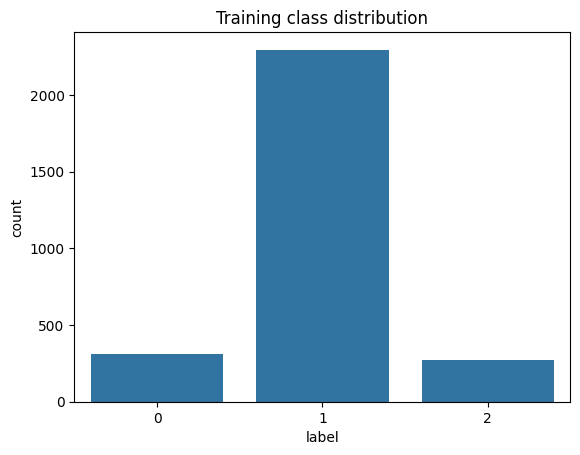

In [19]:
LABEL_NAMES=["Against","Favour","None"]
for name,df in [("Train",train_df),("Validation",val_df),("Test",test_df)]:
    counts=df.label.value_counts().reindex([0,1,2],fill_value=0)
    display(pd.DataFrame({"split":name,"class":LABEL_NAMES,"count":counts.values,
                          "percentage":(counts.values/len(df)*100).round(2)}))
classes=np.array([0,1,2]); y_train=train_df.label.to_numpy()
weights_np=compute_class_weight(class_weight="balanced",classes=classes,y=y_train)
class_weights=torch.tensor(weights_np,dtype=torch.float32,device=device)
display(pd.DataFrame({"class":LABEL_NAMES,"train_count":[int((y_train==c).sum()) for c in classes],
                      "weight":weights_np}))
sns.countplot(data=train_df,x="label"); plt.title("Training class distribution"); plt.show()

## 6. Load MuRIL tokenizer and prepare DataLoaders

In [20]:
MODEL_NAME="google/muril-base-cased"
MAX_LENGTH=160
BATCH_SIZE=8  # Reduce to 4 if CUDA out-of-memory
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)
class StanceDataset(Dataset):
    def __init__(self,df):
        self.texts=df.text.astype(str).tolist(); self.labels=df.label.astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        enc=tokenizer(self.texts[i],truncation=True,max_length=MAX_LENGTH,
                      padding="max_length",return_tensors="pt")
        item={k:v.squeeze(0) for k,v in enc.items()}
        item["labels"]=torch.tensor(self.labels[i],dtype=torch.long)
        return item
train_loader=DataLoader(StanceDataset(train_df),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(StanceDataset(val_df),batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(StanceDataset(test_df),batch_size=BATCH_SIZE,shuffle=False)
print("Batches:",len(train_loader),len(val_loader),len(test_loader))

Batches: 359 45 45


## 7. Evaluation and training functions (live batch progress)

In [21]:
def evaluate(model,loader):
    model.eval(); ys=[]; ps=[]; loss_sum=0
    with torch.no_grad():
        for batch in loader:
            batch={k:v.to(device) for k,v in batch.items()}
            labels=batch.pop("labels"); out=model(**batch)
            loss_sum+=nn.CrossEntropyLoss()(out.logits,labels).item()
            ys.extend(labels.cpu().numpy()); ps.extend(out.logits.argmax(1).cpu().numpy())
    return {"loss":loss_sum/max(len(loader),1),"accuracy":accuracy_score(ys,ps),
            "macro_f1":f1_score(ys,ps,labels=[0,1,2],average="macro",zero_division=0),
            "labels":np.array(ys),"predictions":np.array(ps)}

def train_experiment(name,weighted,epochs=3,lr=2e-5):
    print(f"Training {name}; weighted={weighted}")
    model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,num_labels=3,id2label={0:"Against",1:"Favour",2:"None"},
        label2id={"Against":0,"Favour":1,"None":2}).to(device)
    loss_fn=nn.CrossEntropyLoss(weight=class_weights) if weighted else nn.CrossEntropyLoss()
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=0.01)
    total_steps=len(train_loader)*epochs
    scheduler=get_linear_schedule_with_warmup(optimizer,int(.1*total_steps),total_steps)
    best_f1=-1; best_state=None; history=[]
    for epoch in range(epochs):
        model.train(); total=0
        bar=tqdm(train_loader,desc=f"{name} epoch {epoch+1}/{epochs}")
        for batch in bar:
            batch={k:v.to(device) for k,v in batch.items()}
            labels=batch.pop("labels"); optimizer.zero_grad(set_to_none=True)
            logits=model(**batch).logits; loss=loss_fn(logits,labels)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step(); scheduler.step(); total+=loss.item()
            bar.set_postfix(loss=f"{loss.item():.4f}")
        vm=evaluate(model,val_loader)
        row={"epoch":epoch+1,"train_loss":total/max(len(train_loader),1),
             "val_loss":vm["loss"],"val_accuracy":vm["accuracy"],"val_macro_f1":vm["macro_f1"]}
        history.append(row); print(row)
        if vm["macro_f1"]>best_f1:
            best_f1=vm["macro_f1"]; best_state=copy.deepcopy(model.state_dict())
    if best_state is not None: model.load_state_dict(best_state)
    return model,pd.DataFrame(history)

## 8. Experiment 1 — MuRIL standard Cross-Entropy

In [22]:
EPOCHS=3
LEARNING_RATE=2e-5
baseline_model,baseline_history=train_experiment("MuRIL standard CE",False,EPOCHS,LEARNING_RATE)
display(baseline_history)

Training MuRIL standard CE; weighted=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

MuRIL standard CE epoch 1/3:   0%|          | 0/359 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.8074842329476869, 'val_loss': 0.6235062145524555, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


MuRIL standard CE epoch 2/3:   0%|          | 0/359 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.6390233965471263, 'val_loss': 0.6257186859846116, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


MuRIL standard CE epoch 3/3:   0%|          | 0/359 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.621538913225065, 'val_loss': 0.5922796530856027, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
0,1,0.807484,0.623506,0.80226,0.296761
1,2,0.639023,0.625719,0.80226,0.296761
2,3,0.621539,0.592280,0.80226,0.296761


## 9. Experiment 2 — MuRIL weighted Cross-Entropy

In [23]:
weighted_model,weighted_history=train_experiment("MuRIL weighted CE",True,EPOCHS,LEARNING_RATE)
display(weighted_history)

Training MuRIL weighted CE; weighted=True


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

MuRIL weighted CE epoch 1/3:   0%|          | 0/359 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.0851994065521156, 'val_loss': 0.9814723650614421, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


MuRIL weighted CE epoch 2/3:   0%|          | 0/359 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.0397012456213863, 'val_loss': 0.8728418085310194, 'val_accuracy': 0.7429378531073446, 'val_macro_f1': 0.3961677129818723}


MuRIL weighted CE epoch 3/3:   0%|          | 0/359 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.9727169617304895, 'val_loss': 0.8287910911771986, 'val_accuracy': 0.7655367231638418, 'val_macro_f1': 0.42819648533934246}


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
0,1,1.085199,0.981472,0.802260,0.296761
1,2,1.039701,0.872842,0.742938,0.396168
2,3,0.972717,0.828791,0.765537,0.428196


## 10. Test evaluation and comparison

,experiment,accuracy,macro_f1
0,MuRIL standard CE,0.802817,0.296875
1,MuRIL weighted CE,0.780282,0.398847


MuRIL standard CE
              precision    recall  f1-score   support

     Against     0.0000    0.0000    0.0000        35
      Favour     0.8028    1.0000    0.8906       285
        None     0.0000    0.0000    0.0000        35

    accuracy                         0.8028       355
   macro avg     0.2676    0.3333    0.2969       355
weighted avg     0.6445    0.8028    0.7150       355



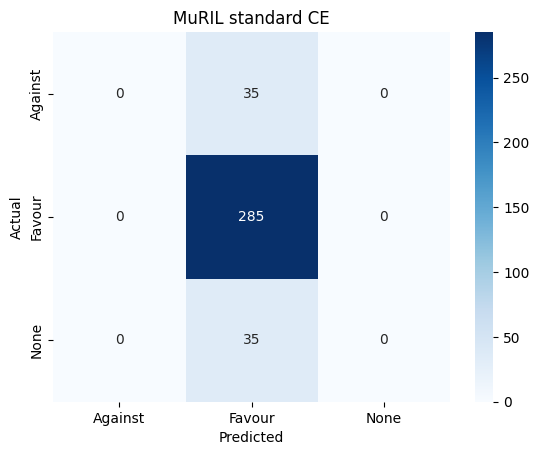

MuRIL weighted CE
              precision    recall  f1-score   support

     Against     0.0000    0.0000    0.0000        35
      Favour     0.8365    0.9333    0.8823       285
        None     0.3143    0.3143    0.3143        35

    accuracy                         0.7803       355
   macro avg     0.3836    0.4159    0.3988       355
weighted avg     0.7025    0.7803    0.7393       355



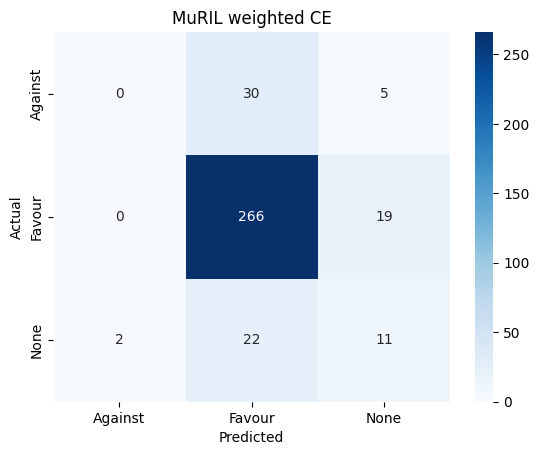

In [24]:
baseline_test=evaluate(baseline_model,test_loader)
weighted_test=evaluate(weighted_model,test_loader)
comparison=pd.DataFrame([
 {"experiment":"MuRIL standard CE","accuracy":baseline_test["accuracy"],"macro_f1":baseline_test["macro_f1"]},
 {"experiment":"MuRIL weighted CE","accuracy":weighted_test["accuracy"],"macro_f1":weighted_test["macro_f1"]}
])
display(comparison)
def report(name,m):
    print(name)
    print(classification_report(m["labels"],m["predictions"],labels=[0,1,2],
          target_names=LABEL_NAMES,digits=4,zero_division=0))
    cm=confusion_matrix(m["labels"],m["predictions"],labels=[0,1,2])
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=LABEL_NAMES,yticklabels=LABEL_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(name); plt.show()
report("MuRIL standard CE",baseline_test); report("MuRIL weighted CE",weighted_test)

In [25]:
# ==========================================
# EXPORT ONLY ESSENTIAL RESULTS FOR ANALYSIS
# No model weights or checkpoint files
# ==========================================

import json
import zipfile
from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

ANALYSIS_DIR = Path(f"/content/{LANGUAGE}_analysis_results")
ANALYSIS_DIR.mkdir(exist_ok=True, parents=True)

# 1. Collect predictions and probabilities
def export_predictions(model, loader, dataframe, experiment, split):

    model.eval()
    actual, predicted, probabilities = [], [], []

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            logits = model(**batch).logits
            probs = torch.softmax(logits, dim=1)

            actual.extend(labels.cpu().numpy())
            predicted.extend(logits.argmax(dim=1).cpu().numpy())
            probabilities.extend(probs.cpu().numpy())

    if len(dataframe) != len(actual):
        raise ValueError(
            f"Prediction count mismatch for {experiment}, {split}"
        )

    result = dataframe[
        ["example_id", "original_text", "text", "label"]
    ].copy().reset_index(drop=True)

    result.rename(columns={"label": "actual_label"}, inplace=True)

    result["predicted_label"] = predicted
    result["correct"] = (
        result["actual_label"] == result["predicted_label"]
    )

    probs = np.asarray(probabilities)

    result["prob_against"] = probs[:, 0]
    result["prob_favour"] = probs[:, 1]
    result["prob_none"] = probs[:, 2]

    result.insert(0, "experiment", experiment)
    result.insert(1, "split", split)

    return result


# 2. Generate predictions for both models
all_predictions = []
all_metrics = []

experiments = [
    ("Standard_CE", baseline_model),
    ("Weighted_CE", weighted_model)
]

splits = [
    ("Validation", val_loader, val_df),
    ("Test", test_loader, test_df)
]

for exp_name, model in experiments:

    for split_name, loader, dataframe in splits:

        predictions = export_predictions(
            model, loader, dataframe, exp_name, split_name
        )

        all_predictions.append(predictions)

        y_true = predictions["actual_label"]
        y_pred = predictions["predicted_label"]

        metrics = {
            "experiment": exp_name,
            "split": split_name,
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(
                y_true, y_pred,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )),
            "classification_report": classification_report(
                y_true, y_pred,
                labels=[0, 1, 2],
                target_names=LABEL_NAMES,
                output_dict=True,
                zero_division=0
            ),
            "confusion_matrix": confusion_matrix(
                y_true, y_pred, labels=[0, 1, 2]
            ).tolist()
        }

        all_metrics.append(metrics)


# 3. Save combined prediction file
pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    ANALYSIS_DIR / "predictions.csv",
    index=False
)


# 4. Save detailed metrics and confusion matrices
with open(
    ANALYSIS_DIR / "metrics.json", "w", encoding="utf-8"
) as f:
    json.dump(all_metrics, f, indent=2, ensure_ascii=False)


# 5. Save training histories
baseline_history.to_csv(
    ANALYSIS_DIR / "baseline_history.csv", index=False
)

weighted_history.to_csv(
    ANALYSIS_DIR / "weighted_history.csv", index=False
)


# 6. Save dataset distributions
distribution_rows = []

for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    counts = df["label"].value_counts().reindex(
        [0, 1, 2], fill_value=0
    )

    for label, count in counts.items():
        distribution_rows.append({
            "split": split_name,
            "label_id": int(label),
            "class": LABEL_NAMES[int(label)],
            "count": int(count)
        })

pd.DataFrame(distribution_rows).to_csv(
    ANALYSIS_DIR / "class_distribution.csv",
    index=False
)


# 7. Save experiment configuration
config = {
    "language": LANGUAGE,
    "model": MODEL_NAME,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_length": MAX_LENGTH,
    "seed": SEED,
    "class_weights": {
        str(int(c)): float(w)
        for c, w in zip(classes, weights_np)
    }
}

with open(
    ANALYSIS_DIR / "config.json", "w", encoding="utf-8"
) as f:
    json.dump(config, f, indent=2)


# 8. Create SMALL ZIP — excludes model checkpoints
ZIP_PATH = Path(f"{LANGUAGE}_analysis_only.zip")

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    for file in ANALYSIS_DIR.iterdir():
        if file.is_file():
            zip_file.write(file, arcname=file.name)


print("Analysis package created:", ZIP_PATH)
print("Size (MB):", round(ZIP_PATH.stat().st_size / (1024**2), 2))

# 9. Download only this compact package
from google.colab import files
files.download(str(ZIP_PATH))

/tmp/ipykernel_512/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)
/tmp/ipykernel_512/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)
/tmp/ipykernel_512/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)


Analysis package created: bengali_analysis_only.zip
Size (MB): 0.32


/tmp/ipykernel_512/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>